In [1]:
# Import required libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder

# Display settings
pd.set_option('display.max_columns', None)

print("All libraries imported successfully!")

All libraries imported successfully!


In [5]:
import os

print(os.listdir('/content'))

['.config', 'online+retail.zip', 'sample_data']


In [6]:
zip_path = '/content/online + retail (1).zip'

In [8]:
import zipfile
import os

zip_path = '/content/online+retail.zip'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall('/content/online_retail')

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [9]:
print(os.listdir('/content/online_retail'))

['Online Retail.xlsx']


In [10]:
import pandas as pd
import numpy as np

df = pd.read_excel('/content/online_retail/Online Retail.xlsx')

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [12]:
# 1. Display first five rows
print("FIRST FIVE ROWS")
display(df.head())

# 2. Dataset dimensions
print("\nDATASET SHAPE")
print(df.shape)

# 3. Column names
print("\nCOLUMN NAMES")
print(df.columns.tolist())

# 4. Dataset information
print("\nDATASET INFORMATION")
df.info()

# 5. Statistical summary
print("\nSTATISTICAL SUMMARY")
display(df.describe())

# 6. Missing values
print("\nMISSING VALUES")
display(df.isnull().sum())

FIRST FIVE ROWS


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



DATASET SHAPE
(541909, 8)

COLUMN NAMES
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB

STATISTICAL SUMMARY


,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303



MISSING VALUES


,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


In [13]:
# Count missing values in each column

missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values)

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [14]:
# Calculate percentage of missing values

missing_percentage = (df.isnull().sum() / len(df)) * 100

print("Missing Value Percentage:")
print(missing_percentage)

Missing Value Percentage:
InvoiceNo       0.000000
StockCode       0.000000
Description     0.268311
Quantity        0.000000
InvoiceDate     0.000000
UnitPrice       0.000000
CustomerID     24.926694
Country         0.000000
dtype: float64


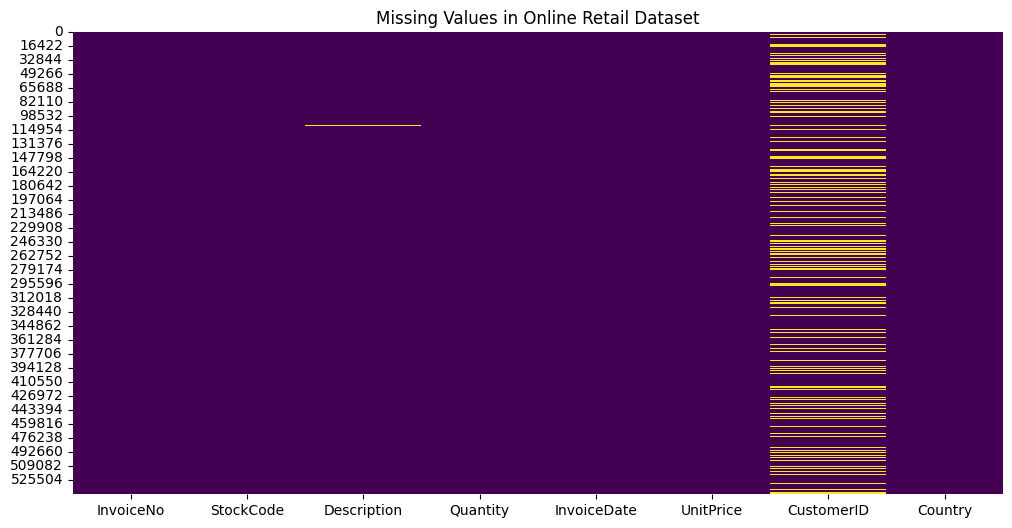

In [15]:
plt.figure(figsize=(12, 6))

sns.heatmap(df.isnull(), cbar=False, cmap='viridis')

plt.title("Missing Values in Online Retail Dataset")
plt.show()

In [16]:
# Count duplicate rows

print("Total Duplicate Rows:", df.duplicated().sum())

Total Duplicate Rows: 5268


In [17]:
# Remove duplicate rows

df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (536641, 8)


In [18]:
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135037
Country,0


In [19]:
# Fill missing product descriptions

df['Description'] = df['Description'].fillna('Unknown')

# Remove rows where CustomerID is missing
df = df.dropna(subset=['CustomerID'])

# Check missing values after treatment

print("Missing Values After Cleaning:")
print(df.isnull().sum())

Missing Values After Cleaning:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64


In [20]:
print("Final Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

display(df.head())

Final Dataset Shape: (401604, 8)

Missing Values:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64

Duplicate Records:
0


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [21]:
print("Quantity Statistics:")
print(df['Quantity'].describe())

print("\nUnitPrice Statistics:")
print(df['UnitPrice'].describe())

Quantity Statistics:
count    401604.000000
mean         12.183273
std         250.283037
min      -80995.000000
25%           2.000000
50%           5.000000
75%          12.000000
max       80995.000000
Name: Quantity, dtype: float64

UnitPrice Statistics:
count    401604.000000
mean          3.474064
std          69.764035
min           0.000000
25%           1.250000
50%           1.950000
75%           3.750000
max       38970.000000
Name: UnitPrice, dtype: float64


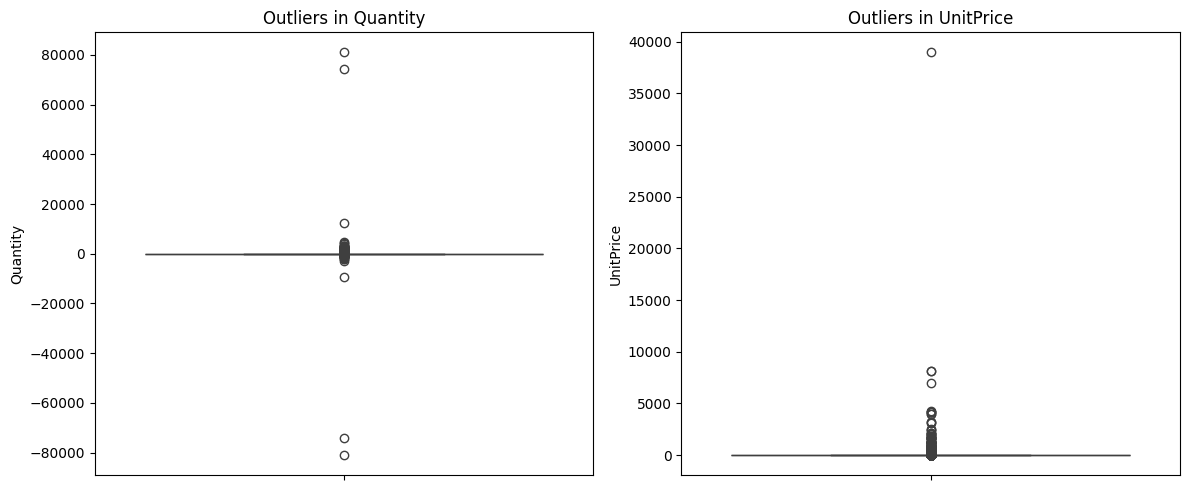

In [22]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(y=df['Quantity'])
plt.title("Outliers in Quantity")

plt.subplot(1, 2, 2)
sns.boxplot(y=df['UnitPrice'])
plt.title("Outliers in UnitPrice")

plt.tight_layout()
plt.show()

In [23]:
# Function to detect outliers using IQR

def detect_outliers(data, column):

    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = data[
        (data[column] < lower_limit) |
        (data[column] > upper_limit)
    ]

    print("\nFeature:", column)
    print("Lower Limit:", lower_limit)
    print("Upper Limit:", upper_limit)
    print("Number of Outliers:", len(outliers))

    return outliers


quantity_outliers = detect_outliers(df, 'Quantity')

price_outliers = detect_outliers(df, 'UnitPrice')


Feature: Quantity
Lower Limit: -13.0
Upper Limit: 27.0
Number of Outliers: 26646

Feature: UnitPrice
Lower Limit: -2.5
Upper Limit: 7.5
Number of Outliers: 35802


In [24]:
# Display highest Quantity values

display(
    df.nlargest(10, 'Quantity')[
        ['InvoiceNo', 'StockCode', 'Description',
         'Quantity', 'UnitPrice']
    ]
)

,InvoiceNo,StockCode,Description,Quantity,UnitPrice
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04
502122,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,0.00
421632,573008,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,0.21
206121,554868,22197,SMALL POPCORN HOLDER,4300,0.72
97432,544612,22053,EMPIRE DESIGN ROSETTE,3906,0.82
270885,560599,18007,ESSENTIAL BALM 3.5g TIN IN ENVELOPE,3186,0.06
52711,540815,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10
160546,550461,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10
433788,573995,16014,SMALL CHINESE STYLE SCISSOR,3000,0.32


In [25]:
# Display highest UnitPrice values

display(
    df.nlargest(10, 'UnitPrice')[
        ['InvoiceNo', 'StockCode', 'Description',
         'Quantity', 'UnitPrice']
    ]
)

,InvoiceNo,StockCode,Description,Quantity,UnitPrice
222681,C556445,M,Manual,-1,38970.00
173277,C551685,POST,POSTAGE,-1,8142.75
173382,551697,POST,POSTAGE,1,8142.75
173391,C551699,M,Manual,-1,6930.00
268027,C560372,M,Manual,-1,4287.63
422351,573077,M,Manual,1,4161.06
422375,C573079,M,Manual,-2,4161.06
422376,573080,M,Manual,1,4161.06
406404,C571750,M,Manual,-1,3949.32
406406,571751,M,Manual,1,3949.32


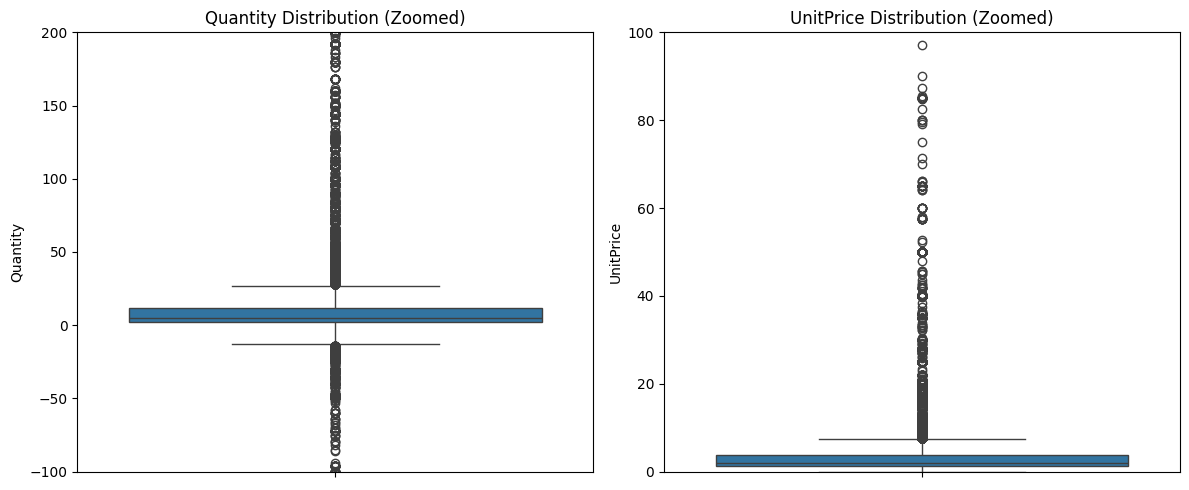

In [26]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(y=df['Quantity'])
plt.ylim(-100, 200)
plt.title("Quantity Distribution (Zoomed)")

plt.subplot(1, 2, 2)
sns.boxplot(y=df['UnitPrice'])
plt.ylim(0, 100)
plt.title("UnitPrice Distribution (Zoomed)")

plt.tight_layout()
plt.show()

In [27]:
# Create a new feature called TotalAmount

df['TotalAmount'] = df['Quantity'] * df['UnitPrice']

# Display the result

display(df[['Quantity', 'UnitPrice', 'TotalAmount']].head(10))

,Quantity,UnitPrice,TotalAmount
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34
5,2,7.65,15.30
6,6,4.25,25.50
7,6,1.85,11.10
8,6,1.85,11.10
9,32,1.69,54.08


In [28]:
# Convert InvoiceDate into datetime format

df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

print(df['InvoiceDate'].dtype)

datetime64[ns]


In [29]:
# Extract year
df['InvoiceYear'] = df['InvoiceDate'].dt.year

# Extract month
df['InvoiceMonth'] = df['InvoiceDate'].dt.month

# Extract day
df['InvoiceDay'] = df['InvoiceDate'].dt.day

# Extract hour
df['InvoiceHour'] = df['InvoiceDate'].dt.hour

# Display new features

display(df[['InvoiceDate', 'InvoiceYear',
            'InvoiceMonth', 'InvoiceDay',
            'InvoiceHour']].head(10))

,InvoiceDate,InvoiceYear,InvoiceMonth,InvoiceDay,InvoiceHour
0,2010-12-01 08:26:00,2010,12,1,8
1,2010-12-01 08:26:00,2010,12,1,8
2,2010-12-01 08:26:00,2010,12,1,8
3,2010-12-01 08:26:00,2010,12,1,8
4,2010-12-01 08:26:00,2010,12,1,8
5,2010-12-01 08:26:00,2010,12,1,8
6,2010-12-01 08:26:00,2010,12,1,8
7,2010-12-01 08:28:00,2010,12,1,8
8,2010-12-01 08:28:00,2010,12,1,8
9,2010-12-01 08:34:00,2010,12,1,8


In [30]:
# Create Weekend feature

df['IsWeekend'] = (
    df['InvoiceDate'].dt.dayofweek >= 5
).astype(int)

display(df[['InvoiceDate', 'IsWeekend']].head(10))

,InvoiceDate,IsWeekend
0,2010-12-01 08:26:00,0
1,2010-12-01 08:26:00,0
2,2010-12-01 08:26:00,0
3,2010-12-01 08:26:00,0
4,2010-12-01 08:26:00,0
5,2010-12-01 08:26:00,0
6,2010-12-01 08:26:00,0
7,2010-12-01 08:28:00,0
8,2010-12-01 08:28:00,0
9,2010-12-01 08:34:00,0


In [31]:
print("Updated Dataset Shape:", df.shape)

print("\nUpdated Columns:")
print(df.columns.tolist())

display(df.head())

Updated Dataset Shape: (401604, 14)

Updated Columns:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'TotalAmount', 'InvoiceYear', 'InvoiceMonth', 'InvoiceDay', 'InvoiceHour', 'IsWeekend']


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount,InvoiceYear,InvoiceMonth,InvoiceDay,InvoiceHour,IsWeekend
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,2010,12,1,8,0
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010,12,1,8,0
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,2010,12,1,8,0
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010,12,1,8,0
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010,12,1,8,0


In [33]:
print("Updated Dataset Shape:", df.shape)

display(df.head())

Updated Dataset Shape: (401604, 14)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount,InvoiceYear,InvoiceMonth,InvoiceDay,InvoiceHour,IsWeekend
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,2010,12,1,8,0
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010,12,1,8,0
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,2010,12,1,8,0
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010,12,1,8,0
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010,12,1,8,0


In [34]:
# Select numerical features for normalization

numerical_features = [
    'Quantity',
    'UnitPrice',
    'TotalAmount'
]

print("Selected Features:", numerical_features)

Selected Features: ['Quantity', 'UnitPrice', 'TotalAmount']


In [35]:
from sklearn.preprocessing import MinMaxScaler

# Create scaler object

scaler = MinMaxScaler()

# Create normalized copies of the features

df[['Quantity_Normalized',
    'UnitPrice_Normalized',
    'TotalAmount_Normalized']] = scaler.fit_transform(
        df[numerical_features]
    )

print("Normalization completed successfully!")

Normalization completed successfully!


In [36]:
display(
    df[['Quantity', 'Quantity_Normalized',
        'UnitPrice', 'UnitPrice_Normalized',
        'TotalAmount', 'TotalAmount_Normalized']].head(10)
)

,Quantity,Quantity_Normalized,UnitPrice,UnitPrice_Normalized,TotalAmount,TotalAmount_Normalized
0,6,0.500037,2.55,0.000065,15.30,0.500045
1,6,0.500037,3.39,0.000087,20.34,0.500060
2,8,0.500049,2.75,0.000071,22.00,0.500065
3,6,0.500037,3.39,0.000087,20.34,0.500060
4,6,0.500037,3.39,0.000087,20.34,0.500060
5,2,0.500012,7.65,0.000196,15.30,0.500045
6,6,0.500037,4.25,0.000109,25.50,0.500076
7,6,0.500037,1.85,0.000047,11.10,0.500033
8,6,0.500037,1.85,0.000047,11.10,0.500033
9,32,0.500198,1.69,0.000043,54.08,0.500161


In [37]:
print("Minimum Values:")
print(df[['Quantity_Normalized',
          'UnitPrice_Normalized',
          'TotalAmount_Normalized']].min())

print("\nMaximum Values:")
print(df[['Quantity_Normalized',
          'UnitPrice_Normalized',
          'TotalAmount_Normalized']].max())

Minimum Values:
Quantity_Normalized       0.0
UnitPrice_Normalized      0.0
TotalAmount_Normalized    0.0
dtype: float64

Maximum Values:
Quantity_Normalized       1.0
UnitPrice_Normalized      1.0
TotalAmount_Normalized    1.0
dtype: float64


In [38]:
# Check unique countries

print("Unique Countries:")
print(df['Country'].unique())

print("\nTotal Number of Countries:")
print(df['Country'].nunique())

Unique Countries:
['United Kingdom' 'France' 'Australia' 'Netherlands' 'Germany' 'Norway'
 'EIRE' 'Switzerland' 'Spain' 'Poland' 'Portugal' 'Italy' 'Belgium'
 'Lithuania' 'Japan' 'Iceland' 'Channel Islands' 'Denmark' 'Cyprus'
 'Sweden' 'Austria' 'Israel' 'Finland' 'Greece' 'Singapore' 'Lebanon'
 'United Arab Emirates' 'Saudi Arabia' 'Czech Republic' 'Canada'
 'Unspecified' 'Brazil' 'USA' 'European Community' 'Bahrain' 'Malta' 'RSA']

Total Number of Countries:
37


In [39]:
# Apply One-Hot Encoding

df_encoded = pd.get_dummies(
    df,
    columns=['Country'],
    prefix='Country',
    dtype=int
)

print("Categorical Encoding Completed!")

Categorical Encoding Completed!


In [40]:
# Display encoded columns

country_columns = [
    col for col in df_encoded.columns
    if col.startswith('Country_')
]

print("New Country Columns:")
print(country_columns)

print("\nTotal Encoded Columns:", len(country_columns))

display(df_encoded.head())

New Country Columns:
['Country_Australia', 'Country_Austria', 'Country_Bahrain', 'Country_Belgium', 'Country_Brazil', 'Country_Canada', 'Country_Channel Islands', 'Country_Cyprus', 'Country_Czech Republic', 'Country_Denmark', 'Country_EIRE', 'Country_European Community', 'Country_Finland', 'Country_France', 'Country_Germany', 'Country_Greece', 'Country_Iceland', 'Country_Israel', 'Country_Italy', 'Country_Japan', 'Country_Lebanon', 'Country_Lithuania', 'Country_Malta', 'Country_Netherlands', 'Country_Norway', 'Country_Poland', 'Country_Portugal', 'Country_RSA', 'Country_Saudi Arabia', 'Country_Singapore', 'Country_Spain', 'Country_Sweden', 'Country_Switzerland', 'Country_USA', 'Country_United Arab Emirates', 'Country_United Kingdom', 'Country_Unspecified']

Total Encoded Columns: 37


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,TotalAmount,InvoiceYear,InvoiceMonth,InvoiceDay,InvoiceHour,IsWeekend,Quantity_Normalized,UnitPrice_Normalized,TotalAmount_Normalized,Country_Australia,Country_Austria,Country_Bahrain,Country_Belgium,Country_Brazil,Country_Canada,Country_Channel Islands,Country_Cyprus,Country_Czech Republic,Country_Denmark,Country_EIRE,Country_European Community,Country_Finland,Country_France,Country_Germany,Country_Greece,Country_Iceland,Country_Israel,Country_Italy,Country_Japan,Country_Lebanon,Country_Lithuania,Country_Malta,Country_Netherlands,Country_Norway,Country_Poland,Country_Portugal,Country_RSA,Country_Saudi Arabia,Country_Singapore,Country_Spain,Country_Sweden,Country_Switzerland,Country_USA,Country_United Arab Emirates,Country_United Kingdom,Country_Unspecified
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,15.30,2010,12,1,8,0,0.500037,0.000065,0.500045,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,20.34,2010,12,1,8,0,0.500037,0.000087,0.500060,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,22.00,2010,12,1,8,0,0.500049,0.000071,0.500065,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,20.34,2010,12,1,8,0,0.500037,0.000087,0.500060,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,20.34,2010,12,1,8,0,0.500037,0.000087,0.500060,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0


In [41]:
print("Original Dataset Shape:", df.shape)

print("Encoded Dataset Shape:", df_encoded.shape)

Original Dataset Shape: (401604, 17)
Encoded Dataset Shape: (401604, 53)


<Figure size 1200x500 with 0 Axes>

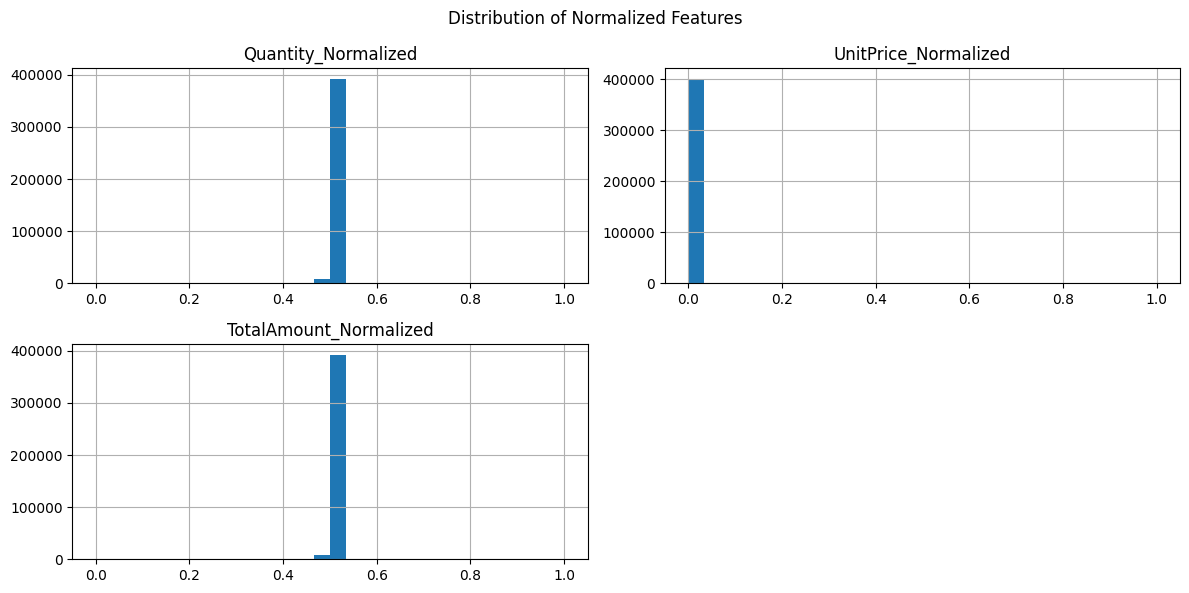

In [42]:
plt.figure(figsize=(12, 5))

df[['Quantity_Normalized',
    'UnitPrice_Normalized',
    'TotalAmount_Normalized']].hist(
        figsize=(12, 6),
        bins=30
    )

plt.suptitle("Distribution of Normalized Features")
plt.tight_layout()
plt.show()

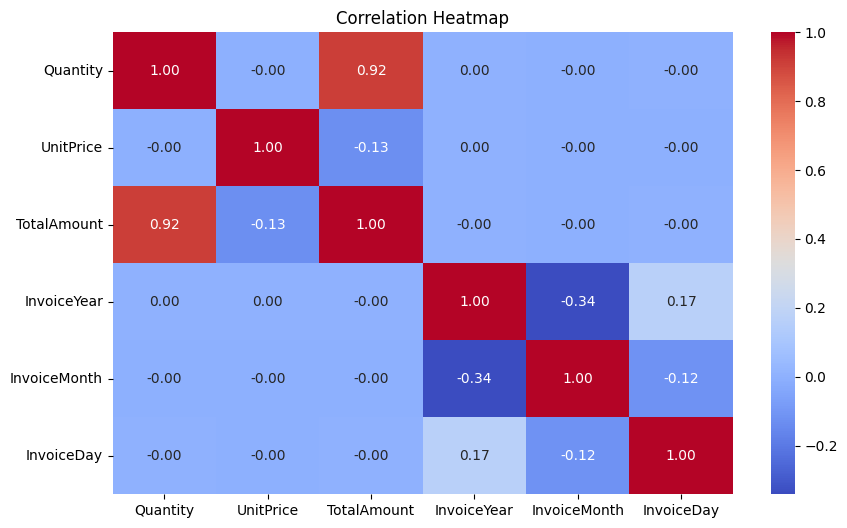

In [43]:
plt.figure(figsize=(10, 6))

correlation = df[
    ['Quantity', 'UnitPrice', 'TotalAmount',
     'InvoiceYear', 'InvoiceMonth', 'InvoiceDay']
].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")
plt.show()

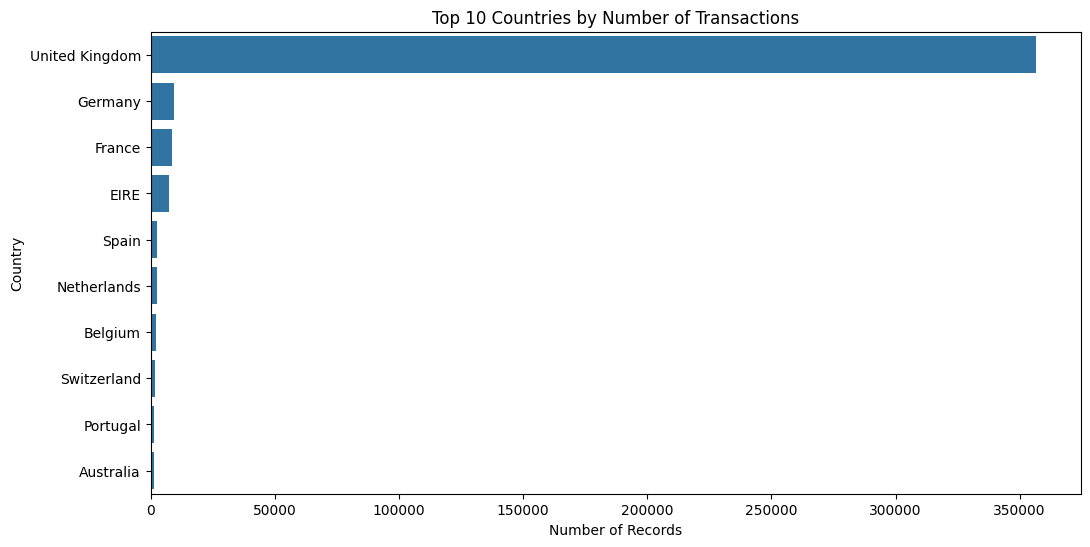

In [44]:
plt.figure(figsize=(12, 6))

top_countries = df['Country'].value_counts().head(10)

sns.barplot(
    x=top_countries.values,
    y=top_countries.index
)

plt.title("Top 10 Countries by Number of Transactions")
plt.xlabel("Number of Records")
plt.ylabel("Country")

plt.show()

In [45]:
# Save processed dataset

df_encoded.to_csv(
    '/content/online_retail_preprocessed.csv',
    index=False
)

print("Preprocessed dataset saved successfully!")

Preprocessed dataset saved successfully!


In [46]:
from google.colab import files

files.download('/content/online_retail_preprocessed.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>